Import Data


In [ ]:
import pandas as pd

df = pd.read_csv("/content/Ecommerce Customers")
df.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


Understand our data

I want to understand who are the target audience we should pay attention at based on their behaviour spend on our ecommerce website


In [ ]:
df['Yearly Amount Spent'].describe()

,Yearly Amount Spent
count,500.000000
mean,499.314038
std,79.314782
min,256.670582
25%,445.038277
50%,498.887875
75%,549.313828
max,765.518462


Using normal distributions to understand the distribution of Yearly Spending of our customer.

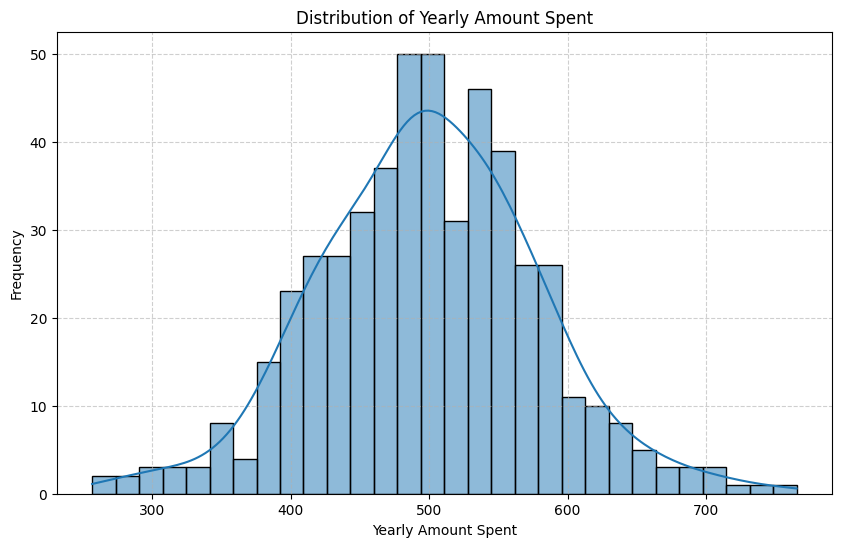

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['Yearly Amount Spent'], kde=True, bins=30)
plt.title('Distribution of Yearly Amount Spent')
plt.xlabel('Yearly Amount Spent')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Adding labels to my dataset based on previous analysis done to separate customer to different groups based on spendings.

LOGIC (Customer Tier):

`Spent > 550 = Tier 2`

`445 < Spent < 550 = Tier 1`

`Else Tier 0`


In [ ]:
def categorize_customer(spent):
    if spent > 550:
        return 2  # VIP (Class 2)
    elif spent > 445:
        return 1  # Normal (Class 1)
    else:
        return 0  # Low Spender (Class 0)

df['Customer_Tier'] = df['Yearly Amount Spent'].apply(categorize_customer)

print(df['Customer_Tier'].value_counts())

df.head()

Customer_Tier
1    252
0    125
2    123
Name: count, dtype: int64


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent,Customer_Tier
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054,2
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933,0
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505,1
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344,2
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092,2


Declare feature and target (X and Y)

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = df[['Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership']].values

y = (df['Yearly Amount Spent'] > 550).astype(int).values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

Understand what is needed for a single neuron

In [ ]:
class SingleNeuron:
    def __init__(self, n_inputs):
        self.weights = np.random.randn(n_inputs) * 0.01
        self.bias = 0.0

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def predict(self, inputs):
        z = np.dot(inputs, self.weights) + self.bias
        return self.sigmoid(z)

Test run for a single neuron

In [ ]:
neuron = SingleNeuron(n_inputs=4)
customer_data = X_test_scaled[0] # Taking a customer from the TEST set now
probability = neuron.predict(customer_data)

print(f"Probability this Test Customer is VIP: {probability:.4f}")
print(f"Actual Class: {'VIP' if y_test[0] == 1 else 'Not VIP'}")

Probability this Test Customer is VIP: 0.4950
Actual Class: Not VIP


Declare three different network structures:

`1 Hidden Layer, 10 Nodes`

`2 Hidden Layers, 100 then 50 nodes`

`5 Hidden Layer, 1000 then 1000 then 500 then 100 then 50 nodes`

In [ ]:
structures = [
    {"name": "Structure 1 (Small)", "layers": (10,)},
    {"name": "Structure 2 (Deep)", "layers": (100, 50)},
    {"name": "Structure 3 (Large)", "layers": (1000,1000,500,100,50)}
]

Initialise MLP with require declaration such as activation, solver, max amount of iterations and random state


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

report_data = []

for struct in structures:
    clf = MLPClassifier(hidden_layer_sizes=struct['layers'],
                        activation='relu',
                        solver='adam',
                        max_iter=2000,
                        random_state=42)

    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    report_data.append({
        "Model": struct['name'],
        "Structure": str(struct['layers']),
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    })

    print(f"Structure: {struct['name']}")
    print(classification_report(y_test, y_pred, target_names=['Normal', 'VIP']))
    print("-" * 60)

Structure: Structure 1 (Small)
              precision    recall  f1-score   support

      Normal       0.98      0.98      0.98       122
         VIP       0.93      0.93      0.93        28

    accuracy                           0.97       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.97      0.97      0.97       150

------------------------------------------------------------
Structure: Structure 2 (Deep)
              precision    recall  f1-score   support

      Normal       0.99      0.98      0.99       122
         VIP       0.93      0.96      0.95        28

    accuracy                           0.98       150
   macro avg       0.96      0.97      0.97       150
weighted avg       0.98      0.98      0.98       150

------------------------------------------------------------
Structure: Structure 3 (Large)
              precision    recall  f1-score   support

      Normal       0.99      0.98      0.99       122
         VIP       0.93

Evaluation metrics.

Comparison between specifications of different layers and nodes


In [ ]:
summary_df = pd.DataFrame(report_data)
print(summary_df.round(4).to_string(index=False))

              Model                  Structure  Accuracy  Precision  Recall  F1-Score
Structure 1 (Small)                      (10,)    0.9733     0.9286  0.9286    0.9286
 Structure 2 (Deep)                  (100, 50)    0.9800     0.9310  0.9643    0.9474
Structure 3 (Large) (1000, 1000, 500, 100, 50)    0.9800     0.9310  0.9643    0.9474


Applying PCA


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)

X_test_pca = pca.transform(X_test_scaled)

print(f"Original Feature Shape: {X_train_scaled.shape}")
print(f"Reduced PCA Shape:      {X_train_pca.shape}")

Original Feature Shape: (350, 4)
Reduced PCA Shape:      (350, 2)


Structure with PCA: Structure 1 (Small)
              precision    recall  f1-score   support

      Normal       0.98      0.97      0.98       122
         VIP       0.87      0.93      0.90        28

    accuracy                           0.96       150
   macro avg       0.93      0.95      0.94       150
weighted avg       0.96      0.96      0.96       150

------------------------------------------------------------
Structure with PCA: Structure 2 (Deep)
              precision    recall  f1-score   support

      Normal       0.99      0.96      0.97       122
         VIP       0.84      0.96      0.90        28

    accuracy                           0.96       150
   macro avg       0.92      0.96      0.94       150
weighted avg       0.96      0.96      0.96       150

------------------------------------------------------------
Structure with PCA: Structure 3 (Large)
              precision    recall  f1-score   support

      Normal       0.97      0.95      0.96       

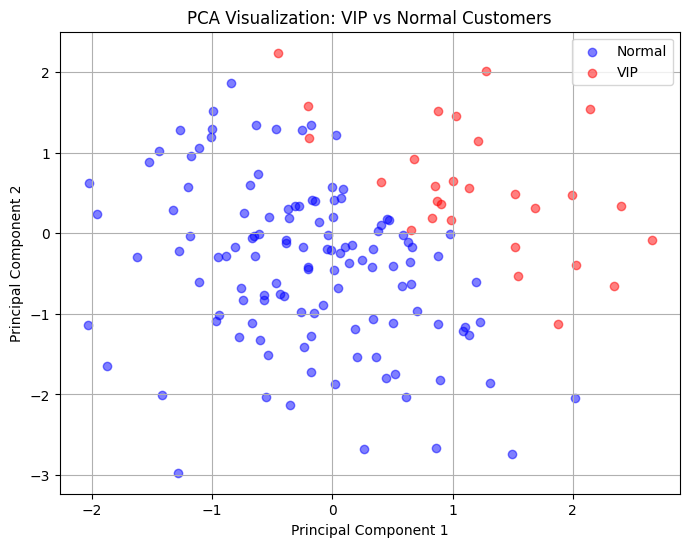

In [ ]:
report_data_pca = []

for struct in structures:
    clf_pca = MLPClassifier(hidden_layer_sizes=struct['layers'],
                            activation='relu',
                            solver='adam',
                            max_iter=2000,
                            random_state=42)

    clf_pca.fit(X_train_pca, y_train)
    y_pred_pca = clf_pca.predict(X_test_pca)

    acc_pca = accuracy_score(y_test, y_pred_pca)
    prec_pca = precision_score(y_test, y_pred_pca)
    rec_pca = recall_score(y_test, y_pred_pca)
    f1_pca = f1_score(y_test, y_pred_pca)

    report_data_pca.append({
        "Model": struct['name'],
        "Structure": str(struct['layers']),
        "Accuracy_PCA": acc_pca,
        "Precision_PCA": prec_pca,
        "Recall_PCA": rec_pca,
        "F1-Score_PCA": f1_pca
    })

    print(f"Structure with PCA: {struct['name']}")
    print(classification_report(y_test, y_pred_pca, target_names=['Normal', 'VIP']))
    print("-" * 60)

plt.figure(figsize=(8, 6))
plt.scatter(X_test_pca[y_test==0, 0], X_test_pca[y_test==0, 1], color='blue', label='Normal', alpha=0.5)
plt.scatter(X_test_pca[y_test==1, 0], X_test_pca[y_test==1, 1], color='red', label='VIP', alpha=0.5)
plt.title("PCA Visualization: VIP vs Normal Customers")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)
plt.show()

PC1 holds: 26.78% of the information
PC2 holds: 26.06% of the information
TOTAL RETAINED: 52.84%
TOTAL LOST:     47.16%

Feature Loadings (Correlations with Components):


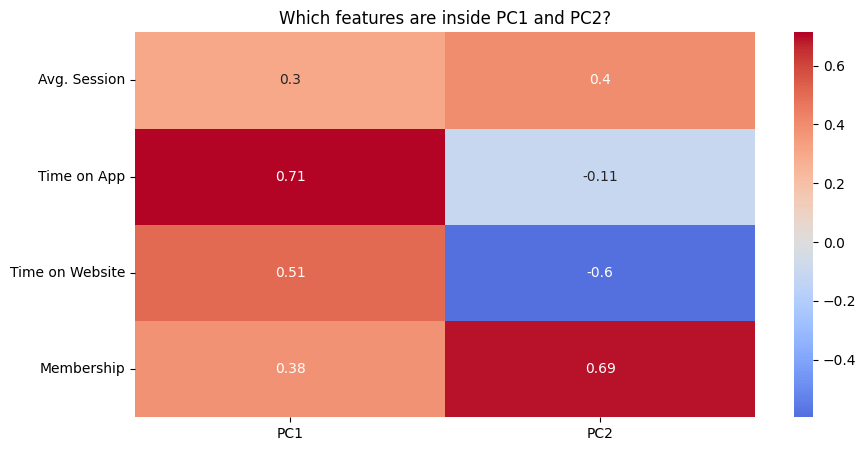

In [ ]:
pca = PCA(n_components=2)
pca.fit(X_train_scaled)

variance_ratios = pca.explained_variance_ratio_
total_variance = sum(variance_ratios) * 100

print(f"PC1 holds: {variance_ratios[0]*100:.2f}% of the information")
print(f"PC2 holds: {variance_ratios[1]*100:.2f}% of the information")
print(f"TOTAL RETAINED: {total_variance:.2f}%")
print(f"TOTAL LOST:     {100 - total_variance:.2f}%")

feature_names = ['Avg. Session', 'Time on App', 'Time on Website', 'Membership']
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=feature_names)

print(f"\nFeature Loadings (Correlations with Components):")
plt.figure(figsize=(10, 5))
sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0)
plt.title("Which features are inside PC1 and PC2?")
plt.show()

/tmp/ipython-input-3147281654.py:68: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels, fontsize=10)


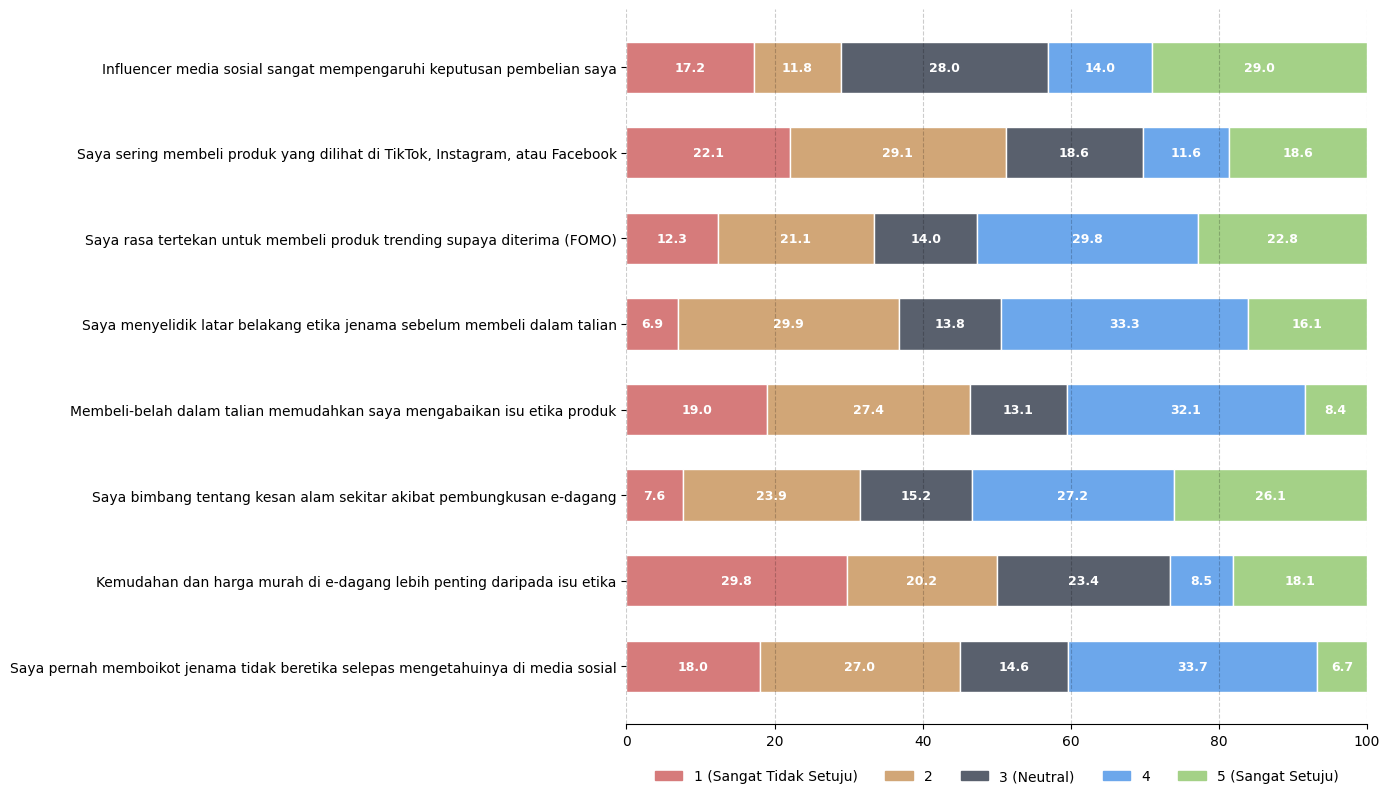

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import random

# 1. Setup Data Labels (Questions)
labels = [
    "Influencer media sosial sangat mempengaruhi keputusan pembelian saya",
    "Saya sering membeli produk yang dilihat di TikTok, Instagram, atau Facebook",
    "Saya rasa tertekan untuk membeli produk trending supaya diterima (FOMO)",
    "Saya menyelidik latar belakang etika jenama sebelum membeli dalam talian",
    "Membeli-belah dalam talian memudahkan saya mengabaikan isu etika produk",
    "Saya bimbang tentang kesan alam sekitar akibat pembungkusan e-dagang",
    "Kemudahan dan harga murah di e-dagang lebih penting daripada isu etika",
    "Saya pernah memboikot jenama tidak beretika selepas mengetahuinya di media sosial"
]
labels.reverse()

# 2. Generate Random Data that sums to 100% for each row
data = []
for _ in range(len(labels)):
    raw_nums = [random.randint(5, 30) for _ in range(5)]
    total = sum(raw_nums)
    # Normalize to percentages
    pcts = [round((x / total) * 100, 1) for x in raw_nums]
    # Adjust the last number to ensure exact 100.0 sum
    pcts[-1] = round(100.0 - sum(pcts[:-1]), 1)
    data.append(pcts)

data = np.array(data)

# 3. Setup Colors and Categories
categories = ['1 (Sangat Tidak Setuju)', '2', '3 (Neutral)', '4', '5 (Sangat Setuju)']
colors = ['#d67b7b', '#d1a677', '#59606d', '#6ca7eb', '#a4d187']
bg_color = 'white'
text_color = 'black'

# 4. Create Plot
fig, ax = plt.subplots(figsize=(14, 8))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# Stacked Logic
left_offsets = np.zeros(len(labels))

for i in range(5):
    # Plot bars
    bars = ax.barh(labels, data[:, i], left=left_offsets, color=colors[i], height=0.6, edgecolor=bg_color)

    # Add text labels inside bars
    for bar, value in zip(bars, data[:, i]):
        if value > 4:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_y() + bar.get_height() / 2,
                    f"{value}", ha='center', va='center', color='white', fontsize=9, fontweight='bold')

    # Update offset
    left_offsets += data[:, i]

# 5. Styling
ax.set_xlim(0, 100)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color(text_color)
ax.tick_params(axis='x', colors=text_color)
ax.tick_params(axis='y', colors=text_color)

# Customizing Y-axis labels
ax.set_yticklabels(labels, fontsize=10)

# Add Legend
handles = [plt.Rectangle((0,0),1,1, color=c) for c in colors]
ax.legend(handles, categories, loc='lower center', bbox_to_anchor=(0.5, -0.1),
          ncol=5, frameon=False, labelcolor=text_color)

# Add faint vertical grid lines
ax.grid(axis='x', linestyle='--', alpha=0.2, color='black')

plt.tight_layout()
plt.show()